# Lecture 3: a variational autoencoder, from model to one update

70-minute slide-led lecture companion. The same binary MNIST observation convention and held test image90 carry over from Lecture 2. Existing trained VAE checkpoints are replayed. All displayed new arithmetic and the inspected SGD update run locally; weights on disk are not changed.

The package is offline and contains its data and checkpoints. Run top-to-bottom from this lecture folder. Requirements: Torch, NumPy, Matplotlib. `logvar` always means log variance. Pixel and latent dimensions are summed, then the batch is averaged.

In [1]:
from pathlib import Path
import sys, json, math, copy
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.nn import functional as F
from IPython.display import display, Image, SVG
ROOT = Path.cwd()
if not (ROOT / "data/mnist-snapshot.npz").exists():
    raise RuntimeError("Run this notebook with its lecture folder as the working directory.")
sys.path.insert(0, str(ROOT / "notebooks"))
import lab
lab.ROOT = ROOT
torch.set_num_threads(2)
torch.manual_seed(667)
d = lab.data()
x_train, x_test = d["train"], d["test"]
held3 = x_test[90:91]
fixtures = json.loads((ROOT / "data/fixtures.json").read_text())
print("Torch", torch.__version__)
print("Snapshot:", tuple(x_train.shape), tuple(x_test.shape))
print("Binary observations:", torch.unique(x_test).tolist())
print("Held image: official test index90, label", int(d["test_labels"][90]))
assert torch.all((x_test == 0) | (x_test == 1))
assert int(d["test_labels"][90]) == 3


Torch 2.13.0
Snapshot: (256, 28, 28) (2000, 28, 28)
Binary observations: [0.0, 1.0]
Held image: official test index90, label 3


In [2]:
def show_grid(images, columns=10, title=""):
    images = np.asarray(images).reshape(-1,28,28)
    rows = int(np.ceil(len(images)/columns))
    fig, axes = plt.subplots(rows, columns, figsize=(columns*1.2,rows*1.2), squeeze=False)
    for ax in axes.flat: ax.axis("off")
    for ax, img in zip(axes.flat, images): ax.imshow(img,cmap="gray_r",vmin=0,vmax=1)
    fig.suptitle(title)
    plt.tight_layout(); plt.show()


## 1. The generative story
Draw z from N(0,I), compute Bernoulli logits, then draw binary pixels. A probability image is not the same object as a sampled observation.

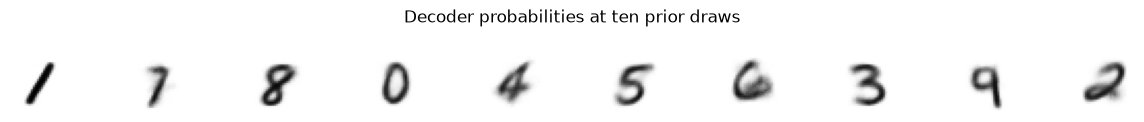

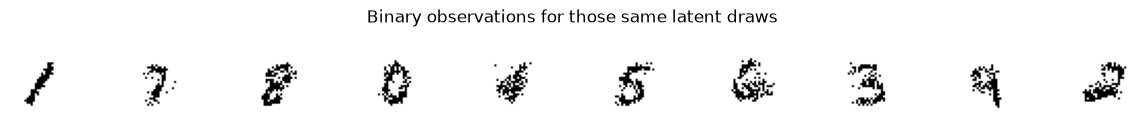

Observation support: [0.0, 1.0]


In [3]:
vae=lab.model("vae2")
with torch.no_grad():
    z=torch.randn(10,2,generator=torch.Generator().manual_seed(667))
    probability=vae.decoder(z).sigmoid()
    observation=torch.bernoulli(probability,generator=torch.Generator().manual_seed(669))
show_grid(probability,10,"Decoder probabilities at ten prior draws")
show_grid(observation,10,"Binary observations for those same latent draws")
print("Observation support:",torch.unique(observation).tolist())

## 2. What q does the encoder assign to the held 3?
The encoder returns means and log variances. Its weights are shared; its outputs depend on the image. The following epsilon is a chosen reproducible teaching input, not an empirically estimated parameter.

mu [[ 0.30405134 -1.9321841 ]]
logvar [[-6.1056004 -5.9966793]]
std [[0.0472265 0.0498698]]
epsilon [[ 0.62 -1.15]]
z [[ 0.33333176 -1.9895344 ]]
one-draw reconstruction NLL, exact prior KL, negative ELBO estimate: 122.2620849609375 6.9663896560668945 129.2284698486328


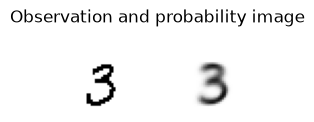

In [4]:
with torch.no_grad():
    mu,logvar=vae.encoder(held3)
    std=torch.exp(.5*logvar)
    epsilon=torch.tensor([[.62,-1.15]])
    z=mu+std*epsilon
    logits=vae.decoder(z)
    recon,kl=lab.terms(logits,held3,mu,logvar)
for name,value in [("mu",mu),("logvar",logvar),("std",std),("epsilon",epsilon),("z",z)]:
    print(name,value.numpy())
print("one-draw reconstruction NLL, exact prior KL, negative ELBO estimate:",float(recon),float(kl),float(recon+kl))
show_grid(torch.cat([held3.flatten(1),logits.sigmoid()]),2,"Observation and probability image")
q=torch.distributions.Normal(mu,std)
p=torch.distributions.Normal(torch.zeros_like(mu),torch.ones_like(std))
library_kl=torch.distributions.kl_divergence(q,p).sum(1)
assert torch.allclose(kl,library_kl,atol=1e-6)

## 3. Before amortisation: fit q for one image
Fix the decoder and optimise free mean and log variance. The optimisation uses 64 fresh epsilon draws per update; a separate 256-draw fixed-noise estimate monitors progress. Neither curve is an exact evidence calculation. The procedure need not reach the encoder’s solution or the exact posterior.

{'step': 0, 'mu': [0.0, 0.0], 'logvar': [0.0, 0.0], 'negative_elbo_estimate': 367.21352039357424}
{'step': 20, 'mu': [0.8639926771957891, -1.4866857957180868], 'logvar': [-1.2321294157205562, -0.7643469802559695], 'negative_elbo_estimate': 211.6497115117627}
{'step': 40, 'mu': [0.29483558391079384, -1.9942300343308128], 'logvar': [-2.235695057886955, -2.2006717769438486], 'negative_elbo_estimate': 155.16918324657465}
{'step': 60, 'mu': [0.2550355570109226, -1.7806992624546925], 'logvar': [-3.2675947991816585, -3.095700262167862], 'negative_elbo_estimate': 138.47079268682384}
{'step': 80, 'mu': [0.28994720823276926, -1.9273323779112344], 'logvar': [-3.907995549350362, -3.512157427871643], 'negative_elbo_estimate': 133.7802304548232}


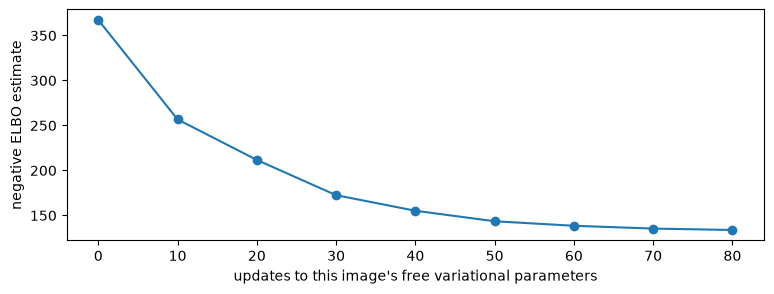

In [5]:
history=lab.fit_one_q(vae,held3,steps=80)
for row in history[::2]:print(row)
plt.figure(figsize=(9,3));plt.plot([r["step"] for r in history],[r["negative_elbo_estimate"] for r in history],"o-")
plt.xlabel("updates to this image's free variational parameters")
plt.ylabel("negative ELBO estimate");plt.show()

**Why amortise?** Repeating this fit for every new image costs repeated optimisation. A shared encoder predicts variational parameters in one pass. It adds a shared-mapping restriction, not a guarantee of exact inference.

## 4. Reparameterisation and an independent gradient check
Fix epsilon when comparing derivatives. The analytic derivatives below are for a chosen scalar loss z². Fresh training noise and fixed gradient-check noise have different purposes.

In [6]:
mu=torch.tensor(.3,dtype=torch.float64,requires_grad=True)
v=torch.tensor(-.4,dtype=torch.float64,requires_grad=True)
epsilon=torch.tensor(.62,dtype=torch.float64)
std=torch.exp(.5*v)
z=mu+std*epsilon
loss=z.square();loss.backward()
analytic_mu=2*z.detach()
analytic_v=z.detach()*std.detach()*epsilon
h=1e-6
fn=lambda mm,vv:(mm+torch.exp(.5*vv)*epsilon).square()
fd_mu=(fn(mu.detach()+h,v.detach())-fn(mu.detach()-h,v.detach()))/(2*h)
fd_v=(fn(mu.detach(),v.detach()+h)-fn(mu.detach(),v.detach()-h))/(2*h)
print("autograd / analytic / finite difference for mu:",float(mu.grad),float(analytic_mu),float(fd_mu))
print("autograd / analytic / finite difference for logvar:",float(v.grad),float(analytic_v),float(fd_v))
assert abs(float(mu.grad-fd_mu))<1e-8
assert abs(float(v.grad-fd_v))<1e-8
print(lab.verify())
print(lab.reconstruction_path_check(vae,x_train[:8]))

autograd / analytic / finite difference for mu: 1.6152261338166976 1.6152261338166976 1.6152261337887275
autograd / analytic / finite difference for logvar: 0.40995494576860436 0.4099549457686044 0.40995494576812064
{'gaussian_KL_library_error': 0.0, 'BCE_hand_error': 2.220446049250313e-16, 'four_pixel_BCE': 1.196004634676759, 'pathwise_grad_mu': [[1.6152261338166976, -4.9418931115739895]], 'pathwise_grad_logvar': [[0.40995494576860436, 3.1404410146112185]], 'checks': 'KL/library; Bernoulli/hand; both reparameterisation derivatives'}
{'objective': 'reconstruction only; no prior KL', 'seed': 675, 'gradient_norm_sums': {'encoder.mu': 224.95479005820263, 'encoder.logvar': 4.217652235751896, 'decoder': 108.42780118345442}, 'passed': True}


## 5. One complete, actual training step
The demonstration copies a trained checkpoint and performs SGD on eight **training** images. A small stated step size keeps the local update inspectable. A fixed epsilon is used for the before/after comparison only. Ordinary training samples fresh epsilon.

In [7]:
model=copy.deepcopy(vae).double()
xb=x_train[:8].double()
epsilon=torch.randn(8,2,generator=torch.Generator().manual_seed(667),dtype=torch.float64)
mu,logvar=model.encoder(xb)
std=torch.exp(.5*logvar)
z=mu+std*epsilon
logits=model.decoder(z)
pixel_nll=F.binary_cross_entropy_with_logits(logits,xb.flatten(1),reduction="none")
reconstruction=pixel_nll.sum(1)
prior_kl=.5*(mu.square()+logvar.exp()-1-logvar).sum(1)
loss=(reconstruction+prior_kl).mean()
model.zero_grad(set_to_none=True);loss.backward()
before={name:parameter.detach().clone() for name,parameter in model.named_parameters()}
gradients={name:float(parameter.grad.norm()) for name,parameter in model.named_parameters()}
eta=1e-6
with torch.no_grad():
    for parameter in model.parameters():parameter-=eta*parameter.grad
    new_logits,new_mu,new_lv,_=model(xb,epsilon)
    rr,kk=lab.terms(new_logits,xb,new_mu,new_lv)
    after=(rr+kk).mean()
print("same-noise loss before/after:",float(loss.detach()),float(after))
for group in ["encoder.mu","encoder.logvar","decoder"]:
    delta=sum(float((parameter.detach()-before[name]).norm()) for name,parameter in model.named_parameters() if name.startswith(group))
    grad=sum(value for name,value in gradients.items() if name.startswith(group))
    print(group,"gradient-norm sum:",grad,"parameter-delta-norm sum:",delta)
    assert grad>0 and delta>0
assert abs(float(after)-fixtures["vae_step"]["after_same_noise"])<1e-8

same-noise loss before/after: 126.01692473981953 125.91750493375213
encoder.mu gradient-norm sum: 319.0115457717059 parameter-delta-norm sum: 0.0003190115457717115
encoder.logvar gradient-norm sum: 2.4673025238756185 parameter-delta-norm sum: 2.467302523887253e-06
decoder gradient-norm sum: 110.6857351492889 parameter-delta-norm sum: 0.00011068573514924168


## 6. What did the recorded model learn?
Decode encoder means for a visual reconstruction check. This is not an estimate of the expected reconstruction term. Separately inspect prior samples.

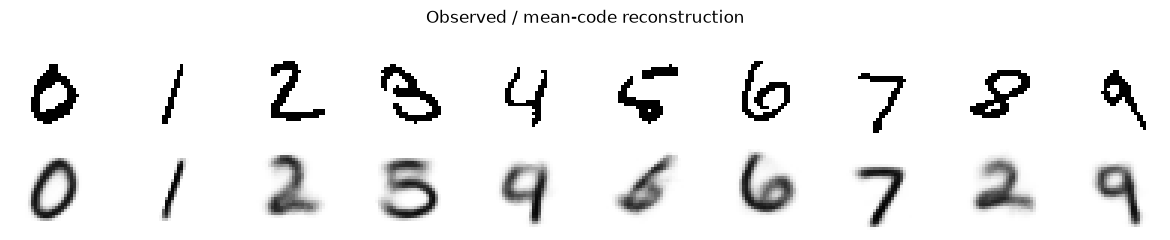

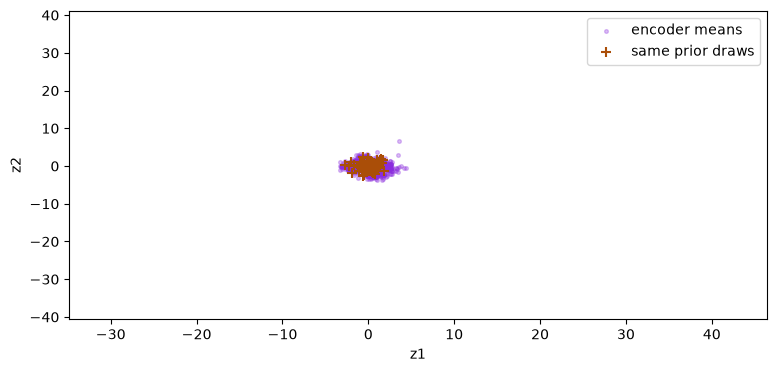

In [8]:
ids=torch.tensor([int(torch.where(d["test_labels"]==i)[0][0]) for i in range(10)])
with torch.no_grad():
    means,logvars=vae.encoder(x_test)
    reconstruction=vae.decoder(means[ids]).sigmoid()
show_grid(torch.cat([x_test[ids].flatten(1),reconstruction]),10,"Observed / mean-code reconstruction")
prior=torch.randn(80,2,generator=torch.Generator().manual_seed(667))
fig,ax=plt.subplots(figsize=(9,4));ax.scatter(means[:,0],means[:,1],s=7,alpha=.3,label="encoder means",c="#8B2CDE")
ax.scatter(prior[:,0],prior[:,1],marker="+",s=50,label="same prior draws",c="#AA4E08")
limits=fixtures["code_axes"];ax.set(xlim=limits[0],ylim=limits[1],xlabel="z1",ylabel="z2");ax.legend();plt.show()

The axes are exactly the AE axes. A mean cloud omits each q covariance, so it is not a full plot of the aggregate posterior. A normal-looking cloud alone does not prove matching distributions.

## 7. Compare recorded dimensions and KL weights carefully
The βKL=1 and βKL=8 two-dimensional checkpoints used the same architecture, seed and 40-epoch schedule. These are different objectives. Evaluate one-draw reconstruction estimates with a stated seed, plus analytic prior KL; do not call the prior KL the unknown posterior gap.

In [9]:
for name in ["vae2","vae16","vae2b8"]:
    model=lab.model(name)
    epsilon=torch.randn(len(x_test),model.encoder.mu.out_features,generator=torch.Generator().manual_seed(673))
    with torch.no_grad():
        logits,mu,lv,_=model(x_test,epsilon)
        recon,kl=lab.terms(logits,x_test,mu,lv)
    print(name,"reconstruction:",float(recon.mean()),"prior KL:",float(kl.mean()),"negative ELBO estimate:",float((recon+kl).mean()))

vae2 reconstruction: 129.00543212890625 prior KL: 7.0763468742370605 negative ELBO estimate: 136.081787109375
vae16 reconstruction: 57.522430419921875 prior KL: 24.26812744140625 negative ELBO estimate: 81.79056549072266


vae2b8 reconstruction: 139.91558837890625 prior KL: 3.869405746459961 negative ELBO estimate: 143.78500366210938


## 8. Optional small training run
This fresh model sees only the bundled 256-image subset and does not reproduce the recorded checkpoint quality. No on-disk weights are overwritten.

In [10]:
RUN_SMALL_TRAINING=False
if RUN_SMALL_TRAINING:
    torch.manual_seed(667)
    model=lab.AutoEncoder(2,True)
    optimizer=torch.optim.Adam(model.parameters(),lr=1e-3)
    for step in range(20):
        logits,mu,logvar,z=model(x_train)  # fresh epsilon every iteration
        recon,kl=lab.terms(logits,x_train,mu,logvar)
        loss=(recon+kl).mean()
        optimizer.zero_grad(set_to_none=True);loss.backward();optimizer.step()
    print("Tiny-subset training loss:",float(loss.detach()))
else:
    print("Optional full training skipped; per-image VI and a real joint update were executed above.")

Optional full training skipped; per-image VI and a real joint update were executed above.


## Exit checks
- **Does zero prior KL imply exact posterior inference?** No. It only says q matches the prior.
- **Does a stable ELBO certify zero posterior gap?** No; the model evidence is generally unavailable.
- **Is βKL=0 automatically a deterministic AE?** No. The sampled latent path may remain.
- **Does prior sampling need an encoder?** No. It uses the prior and decoder.

Model provenance, hashes and original training histories are in `data/`. The saved notebook outputs were executed in the documented local environment.